# Lecture scheduling with genetic algorithms

Seminar Assignment 1 · Tasks 1–4

On the supplied inputs, the custom GA first reached feasibility at generation 155 versus 777 for the default GA. Both Task 3 methods produced a feasible representative with 10 liked hours, 4 disliked hours and a 3-hour workload gap. These are results for one seed (PyGAD 3.9.2).

Run all cells from the assignment folder with a Python kernel and the packages in `requirements.txt`. The examples, experiment inputs and task modules are supplied alongside this notebook.

## Task 1 · Feasibility

Each lecture has three integer genes: start, room and teacher. A lecture appears once by construction. The fitness starts at 10,000 and loses 600 points per unqualified teacher, room-hours violation, overlapping room pair or overlapping teacher pair. Adjacent intervals do not overlap.

In [8]:
from inspect import getsource
import matplotlib.pyplot as plt
import common, Task1, Task2, Task3, Task4

print(getsource(common.fitness_function))
Task1.main()

def fitness_function(ga_instance, solution, solution_idx):
    """Reward schedules with fewer constraint violations."""
    errors = evaluate_schedule(decode_solution(solution))
    return 10_000 - 600 * sum(errors.values())

start..
Best fitness: 10000
  invalid_teacher: 0
  unavailable_classroom: 0
  classroom_overlap: 0
  teacher_overlap: 0
  is_valid: True

Start-End   | Room | Subject          | Teacher
08:00-10:00 | P2   | Programming      | Brian
10:00-13:00 | P1   | Algorithms       | Diana
10:00-12:00 | P2   | Algorithms       | Brian
10:00-12:00 | P3   | Math             | Charles
10:00-12:00 | P4   | Programming      | Anna
12:00-14:00 | P2   | Math             | Charles
12:00-14:00 | P4   | OperatingSystems | Brian
13:00-16:00 | P1   | Programming      | Anna
14:00-16:00 | P2   | OperatingSystems | Diana
14:00-16:00 | P4   | Programming      | Brian
end...


## Task 2 · Search operators

Both runs use the supplied inputs, seed 12, 300 schedules, 80 parents and up to 800 generations. Crossover keeps a lecture's three genes together. Mutation tries one new gene and keeps it when the hard-constraint fitness holds or improves. Callback intervals below are mean milliseconds per completed generation.

In [2]:
print(getsource(Task2.mutation))
Task2.main()

def mutation(children, ga):
    for child in children:
        gene = ga.python_random_generator.randrange(len(child))
        candidate = child.copy()
        candidate[gene] = ga.python_random_generator.choice(ga.gene_space[gene])
        if common.fitness_function(ga, candidate, 0) >= common.fitness_function(ga, child, 0):
            child[gene] = candidate[gene]
    return children

start..
Task 1 (5.851 s)
  crossover: 0.19 ms/generation
  mutation: 3.94 ms/generation
  Generation 0: best fitness 5200
  Generation 1: best fitness 6400
  Generation 3: best fitness 7600
  Generation 6: best fitness 8200
  Generation 14: best fitness 8800
  Generation 152: best fitness 9400
  Generation 777: best fitness 10000
Task 2 (1.017 s)
  crossover: 0.27 ms/generation
  mutation: 4.94 ms/generation
  Generation 0: best fitness 5200
  Generation 1: best fitness 5800
  Generation 2: best fitness 7600
  Generation 4: best fitness 8200
  Generation 8: best fitness 8800
  Generation 18: best fitne

## Task 3 · Teacher preferences and workload

The two runs use the same 64 starting schedules from the Task 2 warm-up and evolve for 80 more generations. Each liked hour earns one point and each disliked hour costs one. Workload gap is the maximum minus minimum teaching hours across all teachers, including those teaching zero hours. A hard violation costs more than the full soft-score range.

The weighted run maximizes net preference minus gap. NSGA-II maximizes net preference and negative gap separately. For comparison, both final populations are ranked by fewest violations, then the weighted score, then the smaller gap. The printed trade-offs are nondominated pairs in the final feasible sample.

In [3]:
print(getsource(Task3.measure))
soft = Task3.compare()
for violations, liked, disliked, gap, hours in soft.values():
    assert sum(hours.values()) == sum(course["duration"] for course in common.LECTURES)
    assert gap == max(hours.values()) - min(hours.values())

def measure(solution, preferences):
    schedule = common.decode_solution(solution)
    violations = sum(common.evaluate_schedule(schedule).values())
    hours = dict.fromkeys(common.TEACHERS, 0)
    liked = disliked = 0
    for lecture in schedule:
        teacher = lecture["teacher"]
        hours[teacher] += lecture["duration"]
        for hour in range(lecture["start"], lecture["end"]):
            start, end = preferences[teacher]["likes"]
            liked += start <= hour < end
            start, end = preferences[teacher]["dislikes"]
            disliked += start <= hour < end
    gap = max(hours.values()) - min(hours.values())
    return violations, liked, disliked, gap, hours

Weighted sum: violations=0, liked=10 h, disliked=4 h, gap=3 h
  Teaching hours: {'Anna': 5, 'Brian': 6, 'Charles': 4, 'Diana': 7}
NSGA-II: violations=0, liked=10 h, disliked=4 h, gap=3 h
  Teaching hours: {'Anna': 5, 'Brian': 6, 'Charles': 4, 'Diana': 7}
  Feasible trade-offs (net preference, gap): [(6,

## Task 4 · Input size, difficulty and population size

The small cases have 10 lectures, 4 rooms and 4 teachers. The supplied case has narrow windows and teacher qualifications. The easy variant uses the same lectures with longer room hours and all teachers qualified. The large cases have 24 two-hour lectures, 6 rooms and 6 teachers. The easy case allows all teachers and 12-hour room windows. The tight case allows one teacher per subject and eight-hour windows. Inputs are in the project folder and `experiments/`.

Each case uses seed 12, 16 parents and a 100-generation cap. Compare Default and Custom at population 60 to test the pair of operators. Compare Custom at 60 and 120 to test population size. A score of 10,000 stops the run. `None` means the budget expired. Runtime includes GA setup and search; for successful runs it measures time through termination at the valid solution.

In [4]:
runs = Task4.experiment()

Small / easy       Default  pop= 60  first valid=2     run=0.005 s  best=10000
Small / easy       Custom   pop= 60  first valid=1     run=0.003 s  best=10000
Small / easy       Custom   pop=120  first valid=2     run=0.009 s  best=10000
Small / supplied   Default  pop= 60  first valid=None  run=0.148 s  best=8800
Small / supplied   Custom   pop= 60  first valid=None  run=0.137 s  best=9400
Small / supplied   Custom   pop=120  first valid=97    run=0.257 s  best=10000
Large / easy       Default  pop= 60  first valid=None  run=0.391 s  best=7000
Large / easy       Custom   pop= 60  first valid=17    run=0.087 s  best=10000
Large / easy       Custom   pop=120  first valid=13    run=0.137 s  best=10000
Large / tight      Default  pop= 60  first valid=None  run=0.399 s  best=-2000
Large / tight      Custom   pop= 60  first valid=None  run=0.445 s  best=6400
Large / tight      Custom   pop=120  first valid=None  run=0.944 s  best=2200


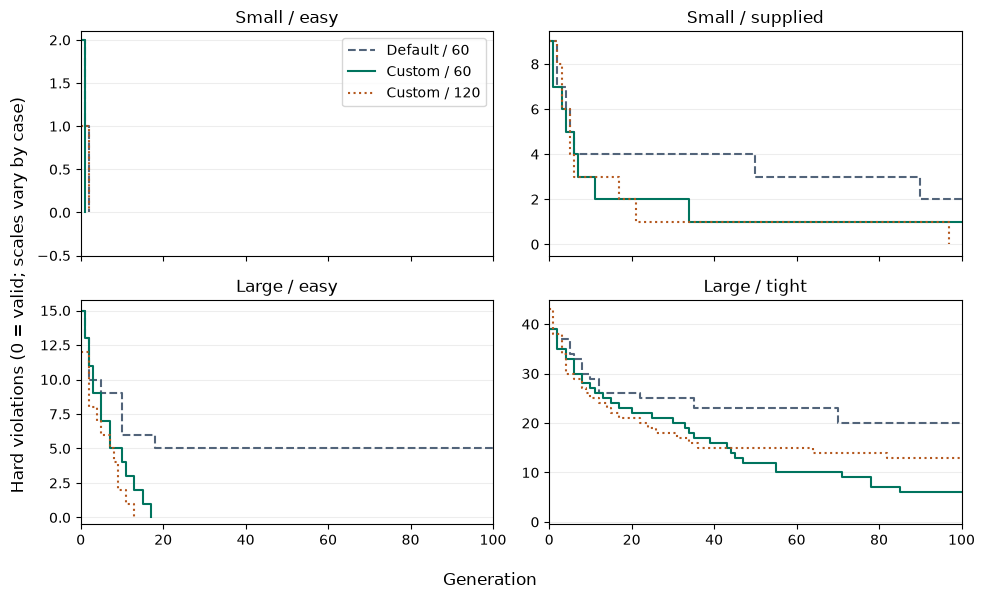

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
cases = list(dict.fromkeys(row[0] for row in runs))
styles = {("Default", 60): ("#52647a", "--"), ("Custom", 60): ("#00745e", "-"),
          ("Custom", 120): ("#b4571d", ":")}
for ax, case in zip(axes.flat, cases):
    for name, method, size, first_valid, elapsed, history in runs:
        if name == case:
            color, line = styles[method, size]
            violations = [(10000 - f) / 600 for f in history]
            ax.step(range(len(history)), violations, where="post", color=color,
                    linestyle=line, label=f"{method} / {size}")
    ax.set_title(case)
    ax.grid(axis="y", alpha=0.22)
    ax.set_xlim(0, 100)
    ax.set_ylim(bottom=-0.5)
axes[0, 0].legend()
fig.supxlabel("Generation")
fig.supylabel("Hard violations (0 = valid; scales vary by case)")
fig.tight_layout()
plt.show()

### Failure check

At population 60 the custom operators solved the large easy case in 17 generations; the default operators still had five violations at generation 100. Increasing the custom population to 120 cut that search to 13 generations but raised runtime from 0.109 to 0.167 seconds. On the tight case, all three configurations missed feasibility, and the larger custom population left more violations (13 versus 6). These paired runs illustrate sensitivity to inputs and settings; estimating typical performance would require more seeds.

For the tight case there is a known feasible schedule: give subject *i* its own room and qualified teacher *i*, with lectures starting at 08, 10, 12 and 14. The check below certifies this witness independently of the GA run.

In [6]:
common.load_data(common.BASE_DIR / "experiments/large_tight")
witness = []
for i in range(6):
    for start in (8, 10, 12, 14):
        witness.extend([start, i, i])
errors = common.evaluate_schedule(common.decode_solution(witness))
assert sum(errors.values()) == 0
print("Known feasible schedule:", errors)
for case, method, size, generation, elapsed, history in runs:
    if case == "Large / tight":
        print(method, size, "population:", (10000 - history[-1]) // 600, "violations at termination")
common.load_data()

Known feasible schedule: {'invalid_teacher': 0, 'unavailable_classroom': 0, 'classroom_overlap': 0, 'teacher_overlap': 0}
Default 60 population: 20 violations at termination
Custom 60 population: 6 violations at termination
Custom 120 population: 13 violations at termination
